# 01 · Exploratory data analysis

## What is in the audio dataset, and what does emotion do to a voice?

This notebook explores the supplied audio dataset from the files themselves. It ends with the preprocessing
decisions that every later notebook depends on.

**How to read it.** Each testable claim is written as a numbered **hypothesis**. The code below it produces the
evidence, a table or a chart. A **verdict** follows (supported / not supported / partly supported), then
**"So we …"**, the decision that the verdict drove. The last cell collects every hypothesis in one table.

Labels used in the text:

| Label | Meaning |
|---|---|
| **[EVIDENCE]** | measured in this notebook |
| **[ASSUMPTION]** | a choice we made that the data cannot prove |

**Which clips each analysis uses.**
- The description of the files (§1–§5, §7) covers all 1,440 clips.
- H6 splits the speakers into 18 **development (dev) speakers** and 6 **held-out speakers**. The held-out speakers
  are kept for the final test.
- The per-emotion profile (H9) and everything in `02_Feature_engineering` use the dev speakers only.

**Runtime.** About 20 seconds on an 8-core laptop, including building the waveform cache on the first run. If
`outputs/tables/acoustics.csv` is deleted, rebuilding it adds between 15 seconds and 5 minutes, depending on the
machine.

**Writes:**
- `outputs/tables/`: `label_index.csv`, `audit_report.csv`, `dataset_profile.json`, `acoustics.csv`,
  `emotion_profile.csv`
- `outputs/figures/`: F01–F06 and F03b

In [1]:
# Setup: make the shared helpers importable, then load the libraries.
# The helpers live in Group-10/shared/, above this folder.
import sys
from pathlib import Path

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import json

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from scipy import stats

import audio_utils as U
import speaker_split as S

import warnings
warnings.filterwarnings(
    "ignore",
    message=".*IProgress not found.*",
)
warnings.filterwarnings(
    "ignore",
    message=".*FigureCanvasAgg is non-interactive.*",
)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Every hypothesis is recorded here as it is tested; the last cell
# prints the full list.
SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    '''Store one hypothesis result and print its verdict.'''
    SUMMARY.append({"H": h, "hypothesis": claim, "verdict": verdict,
                    "evidence": evidence, "so we": decision})
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


from os.path import relpath
print("audio dataset :", relpath(U.data_root(), U.submission_root()))
print("outputs       :",
      relpath(U.tables_dir().parent, U.submission_root()))


audio dataset : ../data
outputs       : EDA and Feature engineering/outputs


---
## 1 · The audio dataset at a glance

The dataset arrives as 24 folders, `Person01` … `Person24`, of `.wav` files. The project brief gives the meaning of
the first field of each filename (the emotion code) and tells us to *ignore the remainder of the file name*.

That leaves two variables:

| Variable | Where it comes from | Role |
|---|---|---|
| `emotion` | filename field 1, via the brief's mapping | the target |
| `speaker` | the folder name | grouping only; **never a model input** |

The speaker is not a model input because a real call does not arrive labelled with who is speaking.

In [2]:
# Build the label index: one row per clip, with the two variables and
# the properties of the file itself (rate, channels, length).
rows = []
for person_dir in sorted(U.data_root().glob("Person*")):
    speaker = U.speaker_from_folder(person_dir)  # from the FOLDER
    for wav in sorted(person_dir.glob("*.wav")):
        x, rate, ch = U.read_wav(wav)
        n_frames = len(x) // ch  # frames per channel
        rows.append({
            "filepath": str(wav.relative_to(U.project_root())),
            "speaker": speaker,
            **U.parse_filename(wav.stem),  # the emotion only
            "sample_rate": rate,
            "channels": ch,
            "n_frames": n_frames,
            "duration_sec": round(n_frames / rate, 3),
        })

index = pd.DataFrame(rows)
print(f"{len(index)} clips indexed; columns: {list(index.columns)}")
index.head(3)

1440 clips indexed; columns: ['filepath', 'speaker', 'emotion_code', 'emotion', 'sample_rate', 'channels', 'n_frames', 'duration_sec']


,filepath,speaker,emotion_code,emotion,sample_rate,channels,n_frames,duration_sec
0,data/Person01/01-01-01-01-01.wav,01,01,neutral,48000,1,158558,3.303
1,data/Person01/01-01-01-02-01.wav,01,01,neutral,48000,1,160160,3.337
2,data/Person01/01-01-02-01-01.wav,01,01,neutral,48000,1,156956,3.270


Before anything is built on the index, it is checked against the counts in the project brief. If any check fails,
the notebook stops, because every later result would inherit the error.

In [3]:
# Seven checks. The brief states 96 neutral clips and 192 of every
# other emotion; an index built from the files must reproduce that.
counts = index["emotion"].value_counts()
checks = {
    "1,440 clips": len(index) == U.N_CLIPS_EXPECTED,
    "24 speakers": index["speaker"].nunique() == U.N_SPEAKERS_EXPECTED,
    "60 clips per speaker": (index.groupby("speaker").size()
                             == U.CLIPS_PER_SPEAKER_EXPECTED).all(),
    "8 emotions": index["emotion"].nunique() == 8,
    "no unknown emotion code": not (index["emotion"] == "UNKNOWN").any(),
    "counts match the brief": (counts["neutral"] == 96 and
                               (counts.drop("neutral") == 192).all()),
    "every file 48 kHz": (index["sample_rate"] == U.SOURCE_RATE).all(),
}
for name, ok in checks.items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
assert all(checks.values()), "Index check failed: stop here."

index.to_csv(U.tables_dir() / "label_index.csv", index=False)
d = index["duration_sec"]
print(f"\nclip length {d.min():.2f}-{d.max():.2f} s, median "
      f"{d.median():.2f} s, total {d.sum() / 60:.1f} minutes")

  [PASS] 1,440 clips
  [PASS] 24 speakers
  [PASS] 60 clips per speaker
  [PASS] 8 emotions
  [PASS] no unknown emotion code
  [PASS] counts match the brief
  [PASS] every file 48 kHz

clip length 2.94-5.27 s, median 3.67 s, total 88.8 minutes


---
## 2 · The eight emotions

### H1 · The eight emotions are equally represented

**Why it matters:** if one emotion is rarer, plain accuracy rewards a model for ignoring it. We would then need a
metric that counts every emotion equally.

saved EDA and Feature engineering/outputs/figures/F01_class_distribution.png


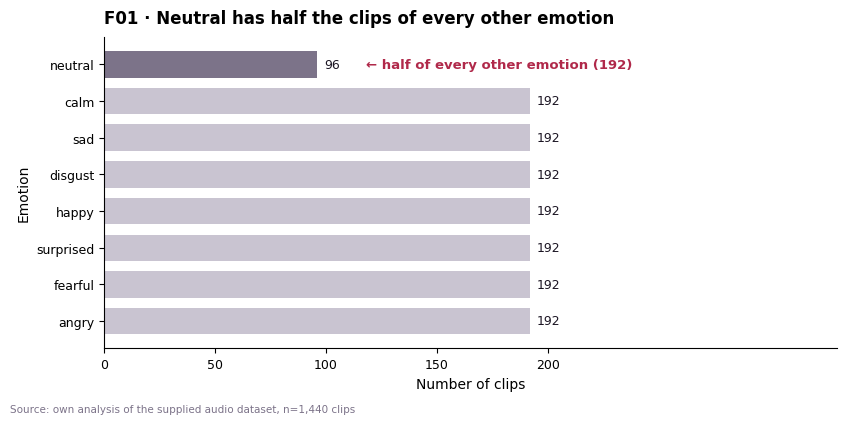

largest / smallest class: 2.0 : 1

H1 · The eight emotions are equally represented
    verdict: NOT SUPPORTED


In [4]:
# F01: clips per emotion. The rare class is drawn in its colour and
# the rest are muted, so the imbalance is the first thing the eye sees.
counts = counts.reindex(U.EMOTION_ORDER)
rare = counts.idxmin()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = [U.EMOTION_COLORS[e] if e == rare else U.MUTED
          for e in counts.index]
ax.barh(range(len(counts)), counts.values, color=colors, height=0.72)
ax.set_yticks(range(len(counts)))
ax.set_yticklabels(counts.index)
ax.invert_yaxis()
for i, v in enumerate(counts.values):
    ax.text(v + 3, i, str(v), va="center", fontsize=9, color=U.INK)
ax.text(counts.min() + 22, 0, f"← half of every other emotion "
        f"({counts.max()})", va="center", fontsize=9.5,
        color=U.ACCENT, fontweight="600")
ax.set_xlim(0, 330)
ax.set_xticks([0, 50, 100, 150, 200])
U.finish_axes(ax, "F01 · Neutral has half the clips of every other emotion",
              "Number of clips", "Emotion")
U.save_figure(fig, "F01_class_distribution.png")
plt.show()

ratio = counts.max() / counts.min()
print(f"largest / smallest class: {ratio:.1f} : 1")
record("H1", "The eight emotions are equally represented",
       "supported" if ratio == 1 else "not supported", "F01",
       "Report macro-F1 (each emotion counts equally); weight classes "
       "in training")

**Verdict: not supported. [EVIDENCE]** Seven emotions have 192 clips each; neutral has 96, a 2 : 1 imbalance.

**So we** report **macro-F1**, the average of the per-emotion F1 scores, so that neutral counts as much as any other
emotion. We also weight classes during training.

---
## 3 · Is the audio clean?

Audio has its own versions of missing values, duplicates and outliers. One sweep over every clip measures what we
need to test the next three hypotheses:

| Measured | Detects |
|---|---|
| channel count | stereo files in a mono dataset |
| waveform fingerprint (MD5 of the decoded audio) | the same recording saved twice |
| peak amplitude | clipping: a signal that hit full scale |
| mean of the waveform | DC offset: a recording shifted off zero |
| loudness (RMS) | clips that may be faulty or silent |
| length after silence trim | how much of each clip is speech (used in §6) |

In [5]:
# One pass over every clip. Each measurement feeds a hypothesis below.
audit = []
for r in index.itertuples():
    path = U.project_root() / r.filepath
    x, rate, ch = U.read_wav(path)
    mono = U.to_mono(x, ch)
    trimmed, _, _ = U.trim_silence(U.resample_48k_to_16k(mono))
    audit.append({
        "filepath": r.filepath, "speaker": r.speaker,
        "emotion": r.emotion, "channels": ch, "is_stereo": ch != 1,
        "peak": round(float(np.abs(mono).max()), 5),
        "is_clipped": bool(np.abs(mono).max() >= 0.999),
        "rms": round(float(np.sqrt((mono ** 2).mean())), 6),
        "dc_offset": round(float(mono.mean()), 6),
        "duration_sec": r.duration_sec,
        "trimmed_sec": round(len(trimmed) / U.TARGET_RATE, 3),
        "md5": U.waveform_md5(path),
    })

audit = pd.DataFrame(audit)
audit["trim_ratio"] = (audit["trimmed_sec"]
                       / audit["duration_sec"]).round(3)
audit["is_low_energy"] = audit["rms"] < 0.001  # a flag, not a verdict
audit["has_dc"] = audit["dc_offset"].abs() > 0.01
audit["is_duplicate"] = audit["md5"].duplicated(keep=False)
audit.to_csv(U.tables_dir() / "audit_report.csv", index=False)
print(f"audited {len(audit)} clips -> outputs/tables/audit_report.csv")

audited 1440 clips -> outputs/tables/audit_report.csv


### H2 · Every file has the same format (mono, 16-bit, 48 kHz)

**Why it matters:** a stereo file read as mono decodes as interleaved noise at twice its true length. It corrupts
every measurement taken from it without raising an error.

In [6]:
# Channel count per file, and proof that the loader fixes stereo.
stereo = audit[audit["is_stereo"]]
print(f"stereo files: {len(stereo)} of {len(audit)}, from "
      f"{stereo['speaker'].nunique()} speakers")
for r in stereo.itertuples():
    print(f"   {r.filepath}   {r.emotion:<9} {r.duration_sec} s")

demo = U.load_clip(U.project_root() / stereo.iloc[0]["filepath"])
print(f"\nafter U.to_mono(), the first one loads as {demo.shape[0]} "
      f"samples = {demo.shape[0] / U.TARGET_RATE:.1f} s (not double)")
record("H2", "Every file has the same format (mono, 16-bit, 48 kHz)",
       "supported" if stereo.empty else "not supported",
       "audit_report.csv",
       "Average the channels to mono before anything else")

stereo files: 5 of 1440, from 3 speakers
   data/Person01/02-01-01-02-01.wav   calm      3.604 s
   data/Person01/08-01-02-02-01.wav   surprised 3.27 s
   data/Person05/02-01-02-02-05.wav   calm      4.238 s
   data/Person20/03-01-02-01-20.wav   happy     3.47 s
   data/Person20/06-01-01-02-20.wav   fearful   4.371 s

after U.to_mono(), the first one loads as 56000 samples = 3.5 s (not double)

H2 · Every file has the same format (mono, 16-bit, 48 kHz)
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** Five files are stereo; the other 1,435 are mono. All are 16-bit, 48 kHz.

**So we** average the two channels into one (`to_mono` in `shared/audio_utils.py`) as the first step of every load.

### H3 · Every clip is a distinct recording

**Why it matters:** if one recording appears twice, a split could put one copy in training and the other in test.
The model would then be scored on audio it has already heard.

In [7]:
# Identical audio has an identical fingerprint, whatever the filename.
dups = audit[audit["is_duplicate"]].sort_values("md5")
for r in dups.itertuples():
    print(f"   {r.filepath}   speaker {r.speaker}   {r.emotion}")
n_unique = audit["md5"].nunique()
print(f"\nunique recordings: {n_unique:,} of {len(audit):,}")
record("H3", "Every clip is a distinct recording",
       "supported" if n_unique == len(audit) else "not supported",
       "audit_report.csv (md5)",
       "Keep both copies together on one side of every split (H19)")

   data/Person07/03-01-02-01-07.wav   speaker 07   happy
   data/Person07/03-01-02-02-07.wav   speaker 07   happy

unique recordings: 1,439 of 1,440

H3 · Every clip is a distinct recording
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** One pair of files is byte-for-byte identical: same speaker, same emotion,
different filenames. The dataset holds **1,439 unique recordings**, not 1,440.

**So we** keep both copies but make sure they can never sit on opposite sides of a split. Splitting by speaker (H6)
does this automatically; H19 in `02_Feature_engineering` shows what a random split would do.

### H4 · No clip is distorted (clipping or DC offset)

**Why it matters:** a clipped waveform has lost its peaks, and a DC offset shifts every sample. Both would distort
loudness, which later turns out to be an important cue.

In [8]:
# Clipping (peak at full scale) and DC offset, per clip.
clipped = audit[audit["is_clipped"]]
for r in clipped.itertuples():
    print(f"clipped: {r.filepath}   {r.emotion}   peak {r.peak}")
print(f"clips at full scale : {len(clipped)}")
print(f"clips with DC offset: {int(audit['has_dc'].sum())}")
print(f"peak amplitude range: {audit['peak'].min():.3f}-"
      f"{audit['peak'].max():.5f}")
record("H4", "No clip is distorted (clipping or DC offset)",
       "supported" if clipped.empty and not audit["has_dc"].any()
       else "largely supported",
       "audit_report.csv", "No correction needed; one marginal clip kept")

clipped: data/Person10/03-02-02-01-10.wav   happy   peak 0.99915
clips at full scale : 1
clips with DC offset: 0
peak amplitude range: 0.006-0.99915

H4 · No clip is distorted (clipping or DC offset)
    verdict: LARGELY SUPPORTED


**Verdict: largely supported. [EVIDENCE]** No clip has a DC offset. One clip touches full scale (peak 0.99915,
fractionally below 1.0).

**So we** make no correction. The one marginal clip stays as it is.

### H5 · The very quiet clips are recording faults

**Why it matters:** the sweep flags 12 clips with loudness (RMS) below 0.001. If they are faults, they should be
removed. If they are genuine, removing them would delete real signal.

In [9]:
# Who are the flagged clips, and where does the threshold sit?
low = audit[audit["is_low_energy"]]
print(f"{len(low)} flagged clips")
print("  by emotion:", low["emotion"].value_counts().to_dict())
print("  by speaker:", low["speaker"].value_counts().to_dict())
pct = stats.percentileofscore(audit["rms"], 0.001)
print(f"\nthe 0.001 threshold sits at the {pct:.1f}th percentile of "
      f"loudness: the quietest ~1% of clips")
quiet = {"calm", "sad", "fearful"}
record("H5", "The very quiet clips are recording faults",
       "not supported" if set(low["emotion"]) <= quiet
       else "needs review",
       "audit_report.csv",
       "Keep all 12; the first sign that loudness tracks emotion")

12 flagged clips
  by emotion: {'calm': 6, 'sad': 5, 'fearful': 1}
  by speaker: {'20': 7, '09': 5}

the 0.001 threshold sits at the 0.8th percentile of loudness: the quietest ~1% of clips

H5 · The very quiet clips are recording faults
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** All 12 are calm, sad or fearful, and they come from just two speakers. They
are quiet people expressing quiet emotions, which is the signal we want to model.

**So we** keep every one of them. This is the first hint that **loudness carries emotion**, tested properly in H10
and H11.

### The dataset figures every document quotes

The figures from §1–§3 are written to one file. The slides, report and video read their dataset numbers from it,
so the four documents cannot disagree.

In [10]:
# Write dataset_profile.json from the index and the audit.
profile = {
    "generated_by": "01_EDA.ipynb",
    "scope": "supplied files only",
    "dataset": {
        "n_clips": int(len(index)),
        "n_speakers": int(index["speaker"].nunique()),
        "clips_per_speaker": int(index.groupby("speaker").size().iloc[0]),
        "n_classes": int(index["emotion"].nunique()),
        "sample_rate_hz": int(index["sample_rate"].iloc[0]),
        "total_minutes": round(float(d.sum() / 60), 1),
        "unit_of_analysis": "one speech clip",
        "target_variable": "emotion (8 classes)",
    },
    "duration_sec": {"min": round(float(d.min()), 2),
                     "max": round(float(d.max()), 2),
                     "mean": round(float(d.mean()), 2),
                     "median": round(float(d.median()), 2)},
    "class_counts": {k: int(v) for k, v in counts.items()},
    "imbalance_ratio": round(float(ratio), 2),
    "quality_findings": {
        "stereo files": int(audit["is_stereo"].sum()),
        "duplicate waveforms": int(audit["is_duplicate"].sum()),
        "clipped files": int(audit["is_clipped"].sum()),
        "files with DC offset": int(audit["has_dc"].sum()),
        "very low energy (flag)": int(audit["is_low_energy"].sum()),
    },
    "unique_waveforms": int(n_unique),
    "stereo_files": stereo["filepath"].tolist(),
    "duplicate_pair": dups["filepath"].tolist(),
    "variables_used": {
        "emotion": "filename field 1, mapping given in the project brief",
        "speaker": "folder name Person01-Person24",
        "not_decoded": "filename fields 2-4, as the project brief says",
    },
}
with open(U.tables_dir() / "dataset_profile.json", "w") as f:
    json.dump(profile, f, indent=2)
print(json.dumps(profile["dataset"], indent=2))

{
  "n_clips": 1440,
  "n_speakers": 24,
  "clips_per_speaker": 60,
  "n_classes": 8,
  "sample_rate_hz": 48000,
  "total_minutes": 88.8,
  "unit_of_analysis": "one speech clip",
  "target_variable": "emotion (8 classes)"
}


---
## 4 · How to split the data

### H6 · Every speaker contributes the same mix of emotions

**Why it matters:** if every speaker recorded every emotion, then under a random split each test clip would have
dozens of clips of the *same voice* in training. A model could score well by recognising who is speaking rather
than what they feel.

saved EDA and Feature engineering/outputs/figures/F02_speaker_class_matrix.png


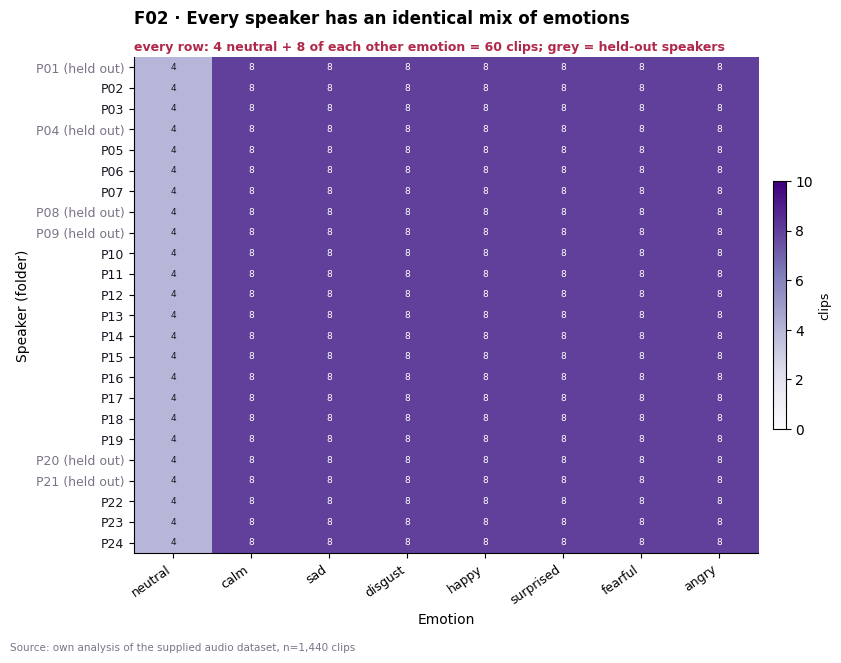

all 24 rows identical: True
dev speakers     : [2, 3, 5, 6, 7, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24] (1080 clips)
held-out speakers: [1, 4, 8, 9, 20, 21] (360 clips)

H6 · Every speaker contributes the same mix of emotions
    verdict: SUPPORTED


In [11]:
# F02: clips per speaker and emotion. The six held-out speakers
# (drawn with a fixed seed, see shared/speaker_split.py) are greyed.
split = S.load_frozen_split()
held_out = {f"{s:02d}" for s in split["test_speakers"]}
mat = (index.groupby(["speaker", "emotion"]).size()
       .unstack(fill_value=0)[U.EMOTION_ORDER])

fig, ax = plt.subplots(figsize=(9, 6.4))
im = ax.imshow(mat.values, aspect="auto", cmap="Purples", vmin=0, vmax=10)
ax.set_xticks(range(len(U.EMOTION_ORDER)))
ax.set_xticklabels(U.EMOTION_ORDER, rotation=35, ha="right")
ax.set_yticks(range(len(mat)))
ax.set_yticklabels([f"P{s}" + (" (held out)" if s in held_out else "")
                    for s in mat.index], fontsize=7)
for lab, s in zip(ax.get_yticklabels(), mat.index):
    lab.set_color(U.GREY if s in held_out else U.INK)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, mat.values[i, j], ha="center", va="center",
                fontsize=6.5,
                color="white" if mat.values[i, j] > 6 else U.INK)
cb = fig.colorbar(im, ax=ax, shrink=0.5, pad=0.02)
cb.set_label("clips", fontsize=9)
U.finish_axes(ax, "F02 · Every speaker has an identical mix of emotions",
              "Emotion", "Speaker (folder)")
# The inference, as a subtitle under the title.
row = mat.iloc[0]
ax.set_title(ax.get_title(loc="left"), loc="left", fontsize=12,
             fontweight="600", pad=24)
ax.text(0, 1.012, f"every row: {row['neutral']} neutral + {row['calm']} "
        f"of each other emotion = {int(row.sum())} clips; grey = "
        "held-out speakers", transform=ax.transAxes, fontsize=9,
        color=U.ACCENT, fontweight="600")
U.save_figure(fig, "F02_speaker_class_matrix.png")
plt.show()

identical = mat.nunique().max() == 1
print(f"all 24 rows identical: {identical}")
print(f"dev speakers     : {split['dev_speakers']} "
      f"({split['n_dev_clips']} clips)")
print(f"held-out speakers: {split['test_speakers']} "
      f"({split['n_test_clips']} clips)")
record("H6", "Every speaker contributes the same mix of emotions",
       "supported" if identical else "not supported", "F02",
       "Split by speaker: 18 dev speakers, 6 held out for the final test")

**Verdict: supported. [EVIDENCE]** All 24 speakers recorded exactly 4 neutral clips and 8 of each other emotion.

**So we split by speaker, never at random.**
- **18 dev speakers** (1,080 clips) are used for all exploration, feature work and model selection.
- **6 held-out speakers** (360 clips) are opened once, for the final test.
- Inside the dev set, cross-validation also holds out whole speakers.

Because every speaker has the same mix, any group of speakers still covers all eight emotions in the same
proportions. The split is fixed by a seed in `shared/speaker_split.py`.

---
## 5 · Preparing the clips

Every clip passes through the same chain before any analysis or model sees it (`load_clip` in
`shared/audio_utils.py`):

| Step | Setting | Reason |
|---|---|---|
| Mix to mono | average the channels | five stereo files (H2) |
| Resample | 48 kHz → **16 kHz** | 48,000 / 16,000 = 3 exactly, so integer decimation with a zero-phase filter; the emotional content of speech sits below 8 kHz; every later step is 3× cheaper |
| Trim silence | frames more than **30 dB** below the clip's loudest frame, from both ends | removes dead air before and after speaking; 30 dB against 40 dB is tested in H13 |
| Fixed window | **3.5 s**, speech centred, crop if longer, zero-pad if shorter | models need equal-length input; tested against 2.5 s and 3.0 s in H14 |
| Loudness | **not normalised** | loudness is a cue we expect to matter (H5); normalising would erase the gap between a shout and a murmur. [ASSUMPTION, tested in H10–H11] |
| Storage | float16 cache, `cache/waves_16000_3.5s_trim30.npy` | halves the file with no effect on features |

### H7 · The preprocessing keeps the audio intact

**Why it matters:** a cache can pass a shape check and still hold silence or damaged audio. Every later result would
then rest on it without anyone noticing.

In [12]:
# Load the cache (built first if missing), then check it.
W = U.load_waveform_cache()
rms = np.sqrt((W ** 2).mean(axis=1))
cache_checks = {
    "shape (1440, 56000)": W.shape == (len(index), U.CLIP_SAMPLES),
    "no NaN or infinite values": bool(np.isfinite(W).all()),
    "no all-silent rows": bool((rms > 0).all()),
    "peaks within 1.5 of full scale": float(np.abs(W).max()) <= 1.5,
}
for name, ok in cache_checks.items():
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
assert all(cache_checks.values()), "Cache check failed."

# Resampling filters overshoot slightly on very loud, sharp sounds.
# If only the loudest clips overshoot, the chain is behaving normally.
peak = np.abs(W).max(axis=1)
over = index.iloc[np.flatnonzero(peak > 1.0)]
n_samples_over = int((np.abs(W) > 1.0).sum())
print(f"\nclips that overshoot full scale: {len(over)} "
      f"({n_samples_over} samples out of {W.size:,})")
print("  their emotions:", over["emotion"].value_counts().to_dict())
print(f"  from {over['speaker'].nunique()} different speakers")

# Spot check: the quietest and loudest clips should be low- and
# high-arousal emotions if the audio survived the chain.
order = np.argsort(rms)
print("\n5 quietest:", list(index.iloc[order[:5]]["emotion"]))
print("5 loudest :", list(index.iloc[order[-5:][::-1]]["emotion"]))
record("H7", "The preprocessing keeps the audio intact",
       "supported" if all(cache_checks.values()) else "not supported",
       "cache checks",
       "Use the cache as is; do not clamp the overshooting peaks")

  [PASS] shape (1440, 56000)
  [PASS] no NaN or infinite values
  [PASS] no all-silent rows
  [PASS] peaks within 1.5 of full scale

clips that overshoot full scale: 11 (24 samples out of 80,640,000)
  their emotions: {'angry': 11}
  from 11 different speakers

5 quietest: ['sad', 'sad', 'sad', 'calm', 'sad']
5 loudest : ['angry', 'angry', 'angry', 'angry', 'angry']

H7 · The preprocessing keeps the audio intact
    verdict: SUPPORTED


**Verdict: supported. [EVIDENCE]** Every structural check passes. The only overshoot is 24 samples out of about
80 million, all in **angry** clips from 11 different speakers. That is normal filter ringing on the loudest signals
in the dataset. It is also independent evidence that anger is the loudest emotion. The quietest clips are
low-arousal emotions and the loudest are angry.

**So we** use the cache as it is. We do not clamp the overshoot, because that would flatten the peaks of exactly
the emotion whose loudness sets it apart.

---
## 6 · How much of each clip is speech?

### H8 · Most of each clip is speech

**Why it matters:** the fixed 3.5 s window pads short clips with zeros. If most of a clip is speech, the padding is
a detail. If not, much of what a model or a statistic sees is silence.

saved EDA and Feature engineering/outputs/figures/F03_duration_distribution.png


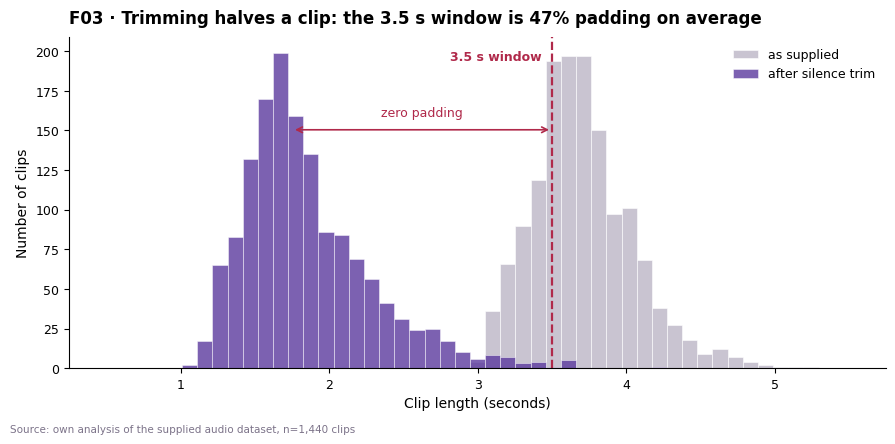

as supplied : median 3.67 s
after trim  : median 1.75 s
trimming removes 50.3% of the average clip
in the 3.5 s window: 7 clips cropped, 1433 padded, mean padding 47.1%

H8 · Most of each clip is speech
    verdict: NOT SUPPORTED


In [13]:
# F03: clip length as supplied vs after trimming, against the window.
raw = audit["duration_sec"].values
trimmed = audit["trimmed_sec"].values
pad_share = np.clip(1 - trimmed / U.CLIP_SECONDS, 0, 1)

fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.linspace(0.5, 5.5, 50)
ax.hist(raw, bins=bins, color=U.MUTED, label="as supplied",
        edgecolor="white", linewidth=0.4)
ax.hist(trimmed, bins=bins, color="#5B3A9E", alpha=0.8,
        label="after silence trim", edgecolor="white", linewidth=0.4)
ax.axvline(U.CLIP_SECONDS, color=U.ACCENT, ls="--", lw=1.6)
top = ax.get_ylim()[1]
ax.text(U.CLIP_SECONDS - 0.07, top * 0.93, f"{U.CLIP_SECONDS} s window",
        color=U.ACCENT, fontsize=9, fontweight="600", ha="right")
ax.annotate("", xy=(U.CLIP_SECONDS, top * 0.72),
            xytext=(np.median(trimmed), top * 0.72),
            arrowprops=dict(arrowstyle="<->", color=U.ACCENT, lw=1.2))
ax.text((np.median(trimmed) + U.CLIP_SECONDS) / 2, top * 0.76,
        "zero padding", color=U.ACCENT, fontsize=9, ha="center")
U.finish_axes(ax, f"F03 · Trimming halves a clip: the {U.CLIP_SECONDS} s "
              f"window is {pad_share.mean() * 100:.0f}% padding on average",
              "Clip length (seconds)", "Number of clips", legend=True)
U.save_figure(fig, "F03_duration_distribution.png")
plt.show()

print(f"as supplied : median {np.median(raw):.2f} s")
print(f"after trim  : median {np.median(trimmed):.2f} s")
print(f"trimming removes {(1 - trimmed / raw).mean() * 100:.1f}% of the "
      f"average clip")
print(f"in the {U.CLIP_SECONDS} s window: {(trimmed > U.CLIP_SECONDS).sum()}"
      f" clips cropped, {(trimmed < U.CLIP_SECONDS).sum()} padded, "
      f"mean padding {pad_share.mean() * 100:.1f}%")
record("H8", "Most of each clip is speech",
       "supported" if np.median(trimmed / raw) > 0.5 else "not supported",
       "F03", "Test whether padding dilutes the features (H12)")

**Verdict: not supported. [EVIDENCE]** Silence trimming removes about half of the average clip: the median length
falls from 3.67 s to 1.75 s. In the 3.5 s window, 1,433 of 1,440 clips are padded, and on average **47% of the
window is zeros**.

**So we** must check whether that padding leaks into the features. A mean or standard deviation taken over the
whole window mixes speech with zeros. That question is H12. First, one more question: does the padding treat every
emotion the same?

### H9 · Padding affects every emotion equally

**Why it matters:** if some emotions are spoken faster or more briefly, their clips carry more padding. Any
statistic averaged over the padded window would then differ between emotions *because of the silence*, not the
voice. That confuses "how much was said" with "how it was said".

*Dev speakers only.* From here on, anything that compares emotions uses the 18 dev speakers, so the held-out
speakers stay unseen.

In [14]:
# The per-emotion profile on dev speakers: speech length, padding
# share, loudness, pitch and voicing. Loudness and pitch come from the
# acoustics table (built first if it is missing).
ac = U.load_acoustics()
assert (ac["filepath"].values == index["filepath"].values).all()
dev = S.dev_mask(index)
S.assert_no_test_speakers(index.loc[dev, "filepath"], "emotion profile")

prof = audit.loc[dev, ["speaker", "emotion", "trimmed_sec"]].copy()
prof["padding_share"] = np.clip(1 - prof["trimmed_sec"]
                                / U.CLIP_SECONDS, 0, 1)
prof["loudness_rms"] = ac.loc[dev, "trimmed_rms"].values
prof["pitch_hz"] = ac.loc[dev, "f0_median_voiced"].values
prof["voiced_frac"] = ac.loc[dev, "voiced_frac"].values

emotion_profile = (prof.groupby("emotion")
                   .agg(clips=("trimmed_sec", "size"),
                        speech_s_median=("trimmed_sec", "median"),
                        padding_pct_mean=("padding_share", "mean"),
                        loudness_rms_median=("loudness_rms", "median"),
                        pitch_hz_median=("pitch_hz", "median"),
                        voiced_frac_median=("voiced_frac", "median"))
                   .reindex(U.EMOTION_ORDER))
emotion_profile["padding_pct_mean"] *= 100
emotion_profile = emotion_profile.round(
    {"speech_s_median": 2, "padding_pct_mean": 1,
     "loudness_rms_median": 4, "pitch_hz_median": 1,
     "voiced_frac_median": 2})
emotion_profile.to_csv(U.tables_dir() / "emotion_profile.csv")

# Do the padding shares differ between emotions more than chance?
# Kruskal-Wallis compares the eight distributions without assuming
# they are normal. Clips from one speaker are not independent, so
# the p-value is indicative only.
h_stat, p_val = stats.kruskal(*[g["padding_share"].values
                                for _, g in prof.groupby("emotion")])
n_dev = int(dev.sum())
print(f"dev clips: {n_dev:,} from {prof['speaker'].nunique()} speakers")
print(f"Kruskal-Wallis across emotions: H = {h_stat:.1f}, "
      f"p = {p_val:.1e}")
emotion_profile

dev clips: 1,080 from 18 speakers
Kruskal-Wallis across emotions: H = 210.3, p = 7.4e-42


,clips,speech_s_median,padding_pct_mean,loudness_rms_median,pitch_hz_median,voiced_frac_median
emotion,,,,,,
neutral,72,1.62,53.5,0.0064,171.7,0.96
calm,144,1.94,41.7,0.0055,164.9,0.95
sad,144,1.80,44.9,0.0087,202.4,0.87
disgust,144,2.04,38.9,0.0122,193.0,0.76
happy,144,1.70,50.2,0.0239,236.9,0.89
surprised,144,1.58,54.4,0.0186,256.2,0.72
fearful,144,1.64,50.4,0.0293,267.8,0.89
angry,144,1.90,45.3,0.0428,247.0,0.85


saved EDA and Feature engineering/outputs/figures/F03b_padding_by_emotion.png


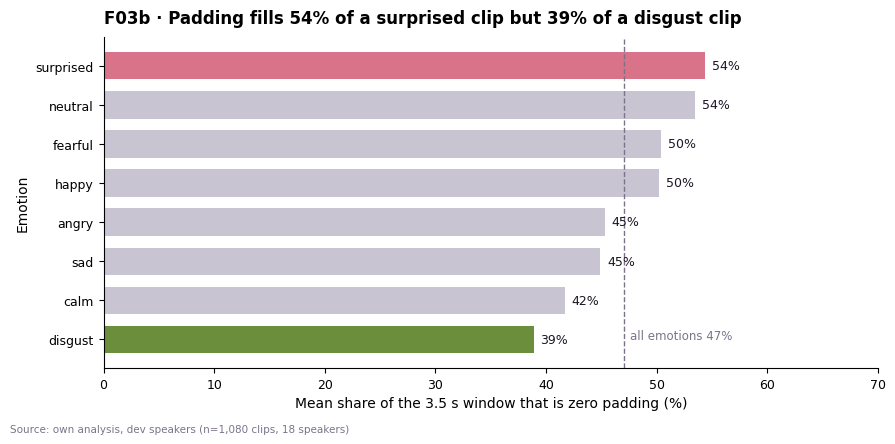

spread between emotions: 15.5 percentage points

H9 · Padding affects every emotion equally
    verdict: NOT SUPPORTED


In [15]:
# F03b: mean padding share per emotion, sorted. The two extremes are
# drawn in their emotion colours; the rest are muted.
pp = emotion_profile["padding_pct_mean"].sort_values()
lo, hi = pp.index[0], pp.index[-1]
DEV_SOURCE = (f"Source: own analysis, dev speakers (n={n_dev:,} clips, "
              f"{prof['speaker'].nunique()} speakers)")

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [U.EMOTION_COLORS[e] if e in (lo, hi) else U.MUTED
          for e in pp.index]
ax.barh(range(len(pp)), pp.values, color=colors, height=0.7)
ax.set_yticks(range(len(pp)))
ax.set_yticklabels(pp.index)
for i, v in enumerate(pp.values):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", fontsize=9,
            color=U.INK)
overall = prof["padding_share"].mean() * 100
ax.axvline(overall, color=U.GREY, ls="--", lw=1)
ax.text(overall + 0.6, 0, f"all emotions {overall:.0f}%",
        fontsize=8.5, color=U.GREY)
ax.set_xlim(0, 70)
U.finish_axes(ax, f"F03b · Padding fills {pp[hi]:.0f}% of a {hi} clip "
              f"but {pp[lo]:.0f}% of a {lo} clip",
              f"Mean share of the {U.CLIP_SECONDS} s window that is zero "
              "padding (%)", "Emotion", source=DEV_SOURCE)
U.save_figure(fig, "F03b_padding_by_emotion.png")
plt.show()

spread = pp[hi] - pp[lo]
print(f"spread between emotions: {spread:.1f} percentage points")
record("H9", "Padding affects every emotion equally",
       "not supported" if p_val < 0.01 else "supported", "F03b",
       "Compute MFCC/spectral statistics over speech frames only (H12)")

**Verdict: not supported. [EVIDENCE]** On the dev speakers, padding fills 54% of the window for a surprised clip but
39% for a disgust clip, a spread of 15.5 percentage points. The difference between emotions is far beyond chance
(Kruskal-Wallis p ≈ 7e-42).

**So we** have a concrete reason to suspect the padded statistics. Part of what separates emotions in a padded
average would be the amount of silence, and the amount of silence depends on the emotion and the speaker in ways a
real call will not repeat.

`02_Feature_engineering` tests this directly (H12): the same features computed over the padded window against
speech frames only.

---
## 7 · What emotion does to a voice

Before any model, the audio itself should show some difference between emotions. The panel below takes one speaker
(the one with median loudness), so the only thing that changes is the emotion.

saved EDA and Feature engineering/outputs/figures/F04_waveform_spectrogram_panel.png


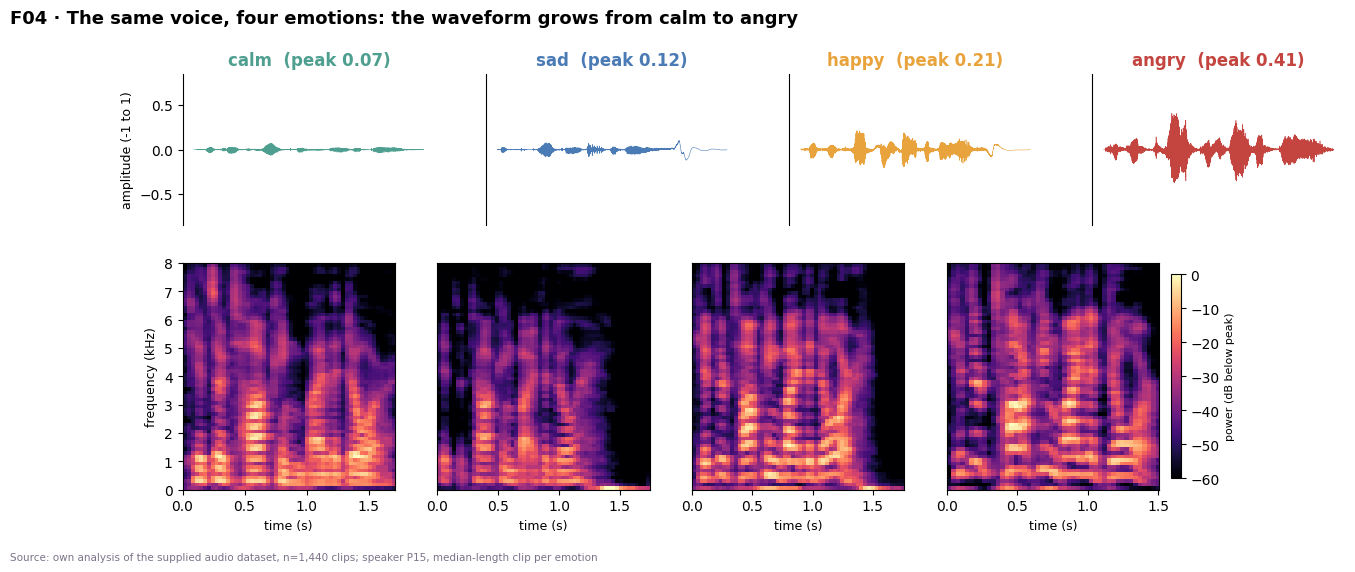

In [16]:
# F04: one speaker, four emotions from low to high arousal. Median-
# loudness speaker, median-length clip of each emotion.
import librosa

spk_med = ac.groupby("speaker")["trimmed_rms"].median()
SPEAKER = spk_med.sub(spk_med.median()).abs().idxmin()
PICK = ["calm", "sad", "happy", "angry"]

fig, axes = plt.subplots(2, 4, figsize=(15, 5.4),
                         gridspec_kw={"height_ratios": [1, 1.5]})
for j, e in enumerate(PICK):
    clip_row = ac[(ac.speaker == SPEAKER) & (ac.emotion == e)]
    clip_row = clip_row.iloc[len(clip_row) // 2]
    y = U.trimmed_signal(U.project_root() / clip_row.filepath)
    t = np.arange(len(y)) / U.TARGET_RATE

    top, bottom = axes[0, j], axes[1, j]
    top.plot(t, y, lw=0.4, color=U.EMOTION_COLORS[e])
    top.set_ylim(-0.85, 0.85)
    top.set_title(f"{e}  (peak {np.abs(y).max():.2f})", fontsize=12,
                  fontweight="600", color=U.EMOTION_COLORS[e])
    top.set_xticks([])
    top.spines[["top", "right", "bottom"]].set_visible(False)
    top.set_ylabel("amplitude (-1 to 1)" if j == 0 else "", fontsize=9)
    if j:
        top.set_yticks([])

    S_db = librosa.power_to_db(librosa.feature.melspectrogram(
        y=y, sr=U.TARGET_RATE, n_mels=64), ref=np.max)
    img = bottom.imshow(S_db, origin="lower", aspect="auto",
                        cmap="magma", vmin=-60, vmax=0,
                        extent=[0, t[-1], 0, U.TARGET_RATE / 2000])
    bottom.set_xlabel("time (s)", fontsize=9)
    bottom.set_ylabel("frequency (kHz)" if j == 0 else "", fontsize=9)
    if j:
        bottom.set_yticks([])

cb = fig.colorbar(img, ax=axes[1, :], shrink=0.9, pad=0.01)
cb.set_label("power (dB below peak)", fontsize=8)
fig.suptitle("F04 · The same voice, four emotions: the waveform grows "
             "from calm to angry",
             fontsize=13, fontweight="600", x=0.01, ha="left", y=1.0)
fig.text(0.01, -0.02, U.SOURCE_NOTE + f"; speaker P{SPEAKER}, "
         "median-length clip per emotion", fontsize=7.5, color=U.GREY)
U.save_figure(fig, "F04_waveform_spectrogram_panel.png")
plt.show()

The contrast is visible before any model. Now we measure it across every clip.

Loudness is measured on the **trimmed speech**, not on the padded cache. The next cell shows why that matters: a
loudness read off the padded window is diluted by the padding, by a different amount for every clip.

In [17]:
# Why loudness is measured on trimmed speech: compare it with the
# same quantity read off the padded cache.
cache_rms = np.sqrt((W ** 2).mean(axis=1))
dilution = ac["trimmed_rms"].values / cache_rms
r_len = np.corrcoef(dilution, ac["trimmed_sec"])[0, 1]
rho = stats.spearmanr(cache_rms, ac["trimmed_rms"])[0]
print(f"trimmed / padded loudness: median {np.median(dilution):.2f}x, "
      f"range {dilution.min():.2f}-{dilution.max():.2f}x")
print(f"dilution vs speech length, correlation {r_len:+.2f}")
print(f"rank agreement of the two measures, rho = {rho:.3f}")

# Can the pitch tracker be trusted? A median inside the adult speech
# band (85-255 Hz) and few estimates at the 400 Hz ceiling would say
# it is tracking voices, not noise.
f0 = ac["f0_median_voiced"].dropna()
near_cap = (f0 >= 390).mean() * 100
print(f"\npitch measured on {len(f0):,} of {len(ac):,} clips; "
      f"median {f0.median():.1f} Hz; "
      f"{((f0 >= 85) & (f0 <= 255)).mean() * 100:.1f}% inside "
      f"85-255 Hz; {near_cap:.1f}% near the 400 Hz ceiling")
assert f0.median() < 260 and near_cap < 5, "pitch tracker unreliable"

trimmed / padded loudness: median 1.41x, range 0.91-1.81x
dilution vs speech length, correlation -0.97
rank agreement of the two measures, rho = 0.994

pitch measured on 1,423 of 1,440 clips; median 213.8 Hz; 68.2% inside 85-255 Hz; 0.6% near the 400 Hz ceiling


The padded measure understates loudness most for the shortest clips (correlation −0.97 with speech length), so the
trimmed measure is the fair one. The pitch tracker passes its check: a median of 213.8 Hz, inside the adult speech
band, with 0.6% of clips near the ceiling.

### H10 · Loudness and pitch rise with emotional arousal

**Why it matters:** if they do, these are cheap, interpretable features that carry emotion. They also justify
leaving loudness un-normalised.

The emotion order in every chart runs from low to high arousal: neutral, calm, sad, disgust, happy, surprised,
fearful, angry. **[ASSUMPTION]** This ordering is our own reading, not a label supplied with the data.

saved EDA and Feature engineering/outputs/figures/F05_energy_pitch_by_emotion.png


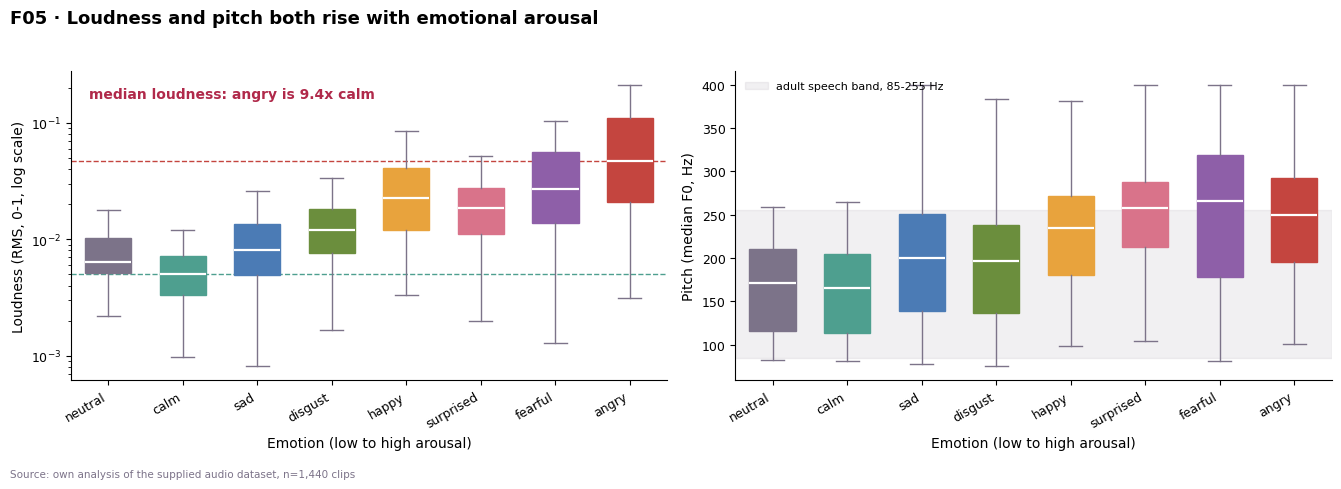

emotion      median RMS   median pitch
  neutral    0.0064      171.7 Hz
  calm       0.0050      164.9 Hz
  sad        0.0081      200.1 Hz
  disgust    0.0121      196.1 Hz
  happy      0.0225      234.9 Hz
  surprised  0.0185      257.2 Hz
  fearful    0.0271      266.3 Hz
  angry      0.0468      249.2 Hz

rank correlation with the arousal order: loudness +0.95, pitch +0.88

H10 · Loudness and pitch rise with emotional arousal
    verdict: SUPPORTED


In [18]:
# F05: loudness and pitch per emotion (all 1,440 clips). The
# calm-to-angry loudness gap is called out, since it is the headline.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
colors = [U.EMOTION_COLORS[e] for e in U.EMOTION_ORDER]
panels = [(axes[0], "trimmed_rms", "Loudness (RMS, 0-1, log scale)",
           True),
          (axes[1], "f0_median_voiced", "Pitch (median F0, Hz)", False)]
for ax, col, label, log in panels:
    data = [ac.loc[ac.emotion == e, col].dropna().values
            for e in U.EMOTION_ORDER]
    bp = ax.boxplot(data, patch_artist=True, widths=0.62,
                    showfliers=False,
                    medianprops=dict(color="white", lw=1.6))
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor(c)
    for part in ("whiskers", "caps"):
        for line in bp[part]:
            line.set_color(U.GREY)
    ax.set_xticks(range(1, len(U.EMOTION_ORDER) + 1))
    ax.set_xticklabels(U.EMOTION_ORDER, rotation=30, ha="right")
    if log:
        ax.set_yscale("log")
    U.finish_axes(ax, "", "Emotion (low to high arousal)", label,
                  source="")

med_rms = ac.groupby("emotion")["trimmed_rms"].median()
med_f0 = ac.groupby("emotion")["f0_median_voiced"].median()
loud_x = med_rms["angry"] / med_rms["calm"]
i_calm = U.EMOTION_ORDER.index("calm") + 1
i_angry = U.EMOTION_ORDER.index("angry") + 1
# Call-out: dashed lines at the calm and angry medians.
for e in ("calm", "angry"):
    axes[0].axhline(med_rms[e], color=U.EMOTION_COLORS[e], ls="--",
                    lw=1, zorder=0)
axes[0].text(0.03, 0.95, f"median loudness: angry is {loud_x:.1f}x calm",
             transform=axes[0].transAxes, fontsize=10, color=U.ACCENT,
             fontweight="600", va="top")
axes[1].axhspan(85, 255, color=U.GREY, alpha=0.10, zorder=0,
                label="adult speech band, 85-255 Hz")
axes[1].legend(loc="upper left", fontsize=8, frameon=False)
fig.suptitle("F05 · Loudness and pitch both rise with emotional arousal",
             fontsize=13, fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, U.SOURCE_NOTE, fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
U.save_figure(fig, "F05_energy_pitch_by_emotion.png")
plt.show()

print("emotion      median RMS   median pitch")
for e in U.EMOTION_ORDER:
    print(f"  {e:<10} {med_rms[e]:.4f}      {med_f0[e]:5.1f} Hz")
arousal_rank = np.arange(len(U.EMOTION_ORDER))
rho_rms = stats.spearmanr(arousal_rank,
                          med_rms.reindex(U.EMOTION_ORDER))[0]
rho_f0 = stats.spearmanr(arousal_rank,
                         med_f0.reindex(U.EMOTION_ORDER))[0]
print(f"\nrank correlation with the arousal order: loudness "
      f"{rho_rms:+.2f}, pitch {rho_f0:+.2f}")
record("H10", "Loudness and pitch rise with emotional arousal",
       "supported" if min(rho_rms, rho_f0) > 0.5 else "partly supported",
       "F05", "Keep loudness and pitch features; do not normalise loudness")

**Verdict: supported. [EVIDENCE]** The median loudness of angry speech is 9.4 times that of calm speech. Median
pitch runs from 165 Hz (calm) to 266 Hz (fearful). Both follow the arousal order closely: rank correlation +0.95 for
loudness, +0.88 for pitch. Pitch is not strictly ordered; angry (249 Hz) sits below fearful.

**So we** keep loudness and pitch in the feature set and leave loudness un-normalised. But a cue can only help if it
belongs to the emotion rather than to the person, which is the next question.

### H11 · Loudness and pitch belong to the emotion, not to the speaker

**Why it matters:** the model will be tested on speakers it has never heard. A feature that mostly describes *who*
is speaking will not transfer to new speakers.

**η² (eta squared)** measures the share of a feature's variance explained by a grouping. We compute it twice for
each measure: once grouping by emotion, once grouping by speaker.

saved EDA and Feature engineering/outputs/figures/F06_emotion_vs_speaker.png


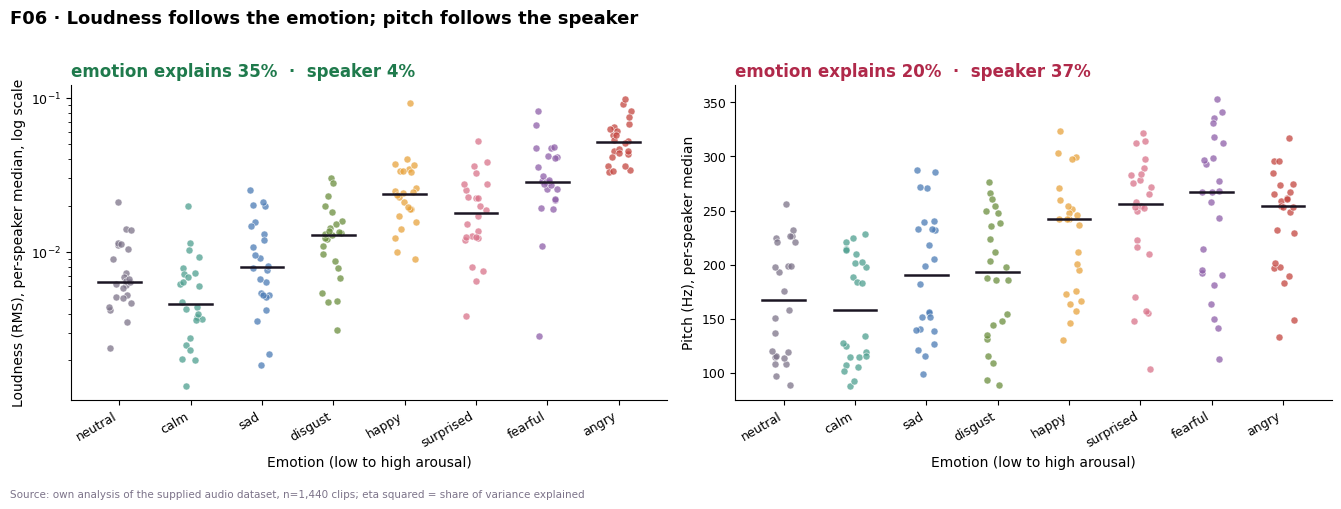

share of variance explained (eta squared)
   loudness : emotion 34.7%   speaker  4.1%
   pitch    : emotion 20.4%   speaker 37.3%

per-speaker median pitch spans 99-276 Hz; per-emotion medians span 165-266 Hz

H11 · Loudness and pitch belong to the emotion, not the speaker
    verdict: PARTLY SUPPORTED


In [19]:
# F06: each dot is one speaker's median for one emotion. The panel
# titles give the eta-squared split; green = mostly emotion,
# red = mostly speaker.
def eta2(frame, col, by):
    '''Share of the variance of `col` explained by the groups `by`.'''
    frame = frame.dropna(subset=[col])
    group_mean = frame.groupby(by)[col].transform("mean")
    return group_mean.var() / frame[col].var()


e_rms, s_rms = eta2(ac, "trimmed_rms", "emotion"), eta2(
    ac, "trimmed_rms", "speaker")
e_f0, s_f0 = eta2(ac, "f0_median_voiced", "emotion"), eta2(
    ac, "f0_median_voiced", "speaker")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
rng = np.random.default_rng(U.SEED)
panels = [(axes[0], "trimmed_rms", "Loudness (RMS), per-speaker median, "
           "log scale", True, e_rms, s_rms),
          (axes[1], "f0_median_voiced", "Pitch (Hz), per-speaker median",
           False, e_f0, s_f0)]
for ax, col, label, log, e_share, s_share in panels:
    per = ac.groupby(["emotion", "speaker"])[col].median().reset_index()
    for i, e in enumerate(U.EMOTION_ORDER):
        v = per.loc[per.emotion == e, col].dropna().values
        ax.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=26,
                   color=U.EMOTION_COLORS[e], alpha=0.75,
                   edgecolor="white", linewidth=0.5, zorder=3)
        ax.plot([i - 0.3, i + 0.3], [np.median(v)] * 2, color=U.INK,
                lw=1.8, zorder=4)
    ax.set_xticks(range(len(U.EMOTION_ORDER)))
    ax.set_xticklabels(U.EMOTION_ORDER, rotation=30, ha="right")
    if log:
        ax.set_yscale("log")
    mostly_emotion = e_share > s_share
    U.finish_axes(ax, f"emotion explains {e_share * 100:.0f}%  ·  "
                  f"speaker {s_share * 100:.0f}%",
                  "Emotion (low to high arousal)", label, source="")
    ax.set_title(ax.get_title(loc="left"), loc="left", fontsize=12,
                 fontweight="600",
                 color=U.GOOD if mostly_emotion else U.ACCENT)

fig.suptitle("F06 · Loudness follows the emotion; pitch follows the "
             "speaker", fontsize=13, fontweight="600", x=0.01, ha="left")
fig.text(0.01, 0.005, U.SOURCE_NOTE + "; eta squared = share of "
         "variance explained", fontsize=7.5, color=U.GREY)
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
U.save_figure(fig, "F06_emotion_vs_speaker.png")
plt.show()

print("share of variance explained (eta squared)")
print(f"   loudness : emotion {e_rms * 100:4.1f}%   speaker "
      f"{s_rms * 100:4.1f}%")
print(f"   pitch    : emotion {e_f0 * 100:4.1f}%   speaker "
      f"{s_f0 * 100:4.1f}%")
sp = ac.groupby("speaker")["f0_median_voiced"].median()
print(f"\nper-speaker median pitch spans {sp.min():.0f}-{sp.max():.0f} Hz;"
      f" per-emotion medians span {med_f0.min():.0f}-"
      f"{med_f0.max():.0f} Hz")
record("H11", "Loudness and pitch belong to the emotion, not the speaker",
       "partly supported" if (e_rms > s_rms) != (e_f0 > s_f0)
       else ("supported" if e_rms > s_rms else "not supported"),
       "F06", "Loudness as measured; pitch z-scored within each speaker")

**Verdict: partly supported. [EVIDENCE]**
- **Loudness is an emotion property:** emotion explains 35% of its variance, the speaker 4%.
- **Pitch is mostly a speaker property:** the speaker explains 37%, the emotion 20%. The gap between speakers'
  typical pitch is wider than the gap between emotions.

**So we**
- keep loudness as measured;
- express pitch **relative to each speaker's own average** (a z-score within the speaker), so that the pitch
  features describe how a person's pitch moves with emotion, not how high their voice is. **[ASSUMPTION]** In
  deployment this needs a baseline of the caller's pitch. It uses no emotion labels.

`02_Feature_engineering` extends this test from two measures to all 512 features (H15).

---
## 8 · Summary

Every hypothesis tested in this notebook, its verdict, and what it changed. The table is built from the results
recorded above.

In [20]:
# All hypotheses in one table, in the order they were tested.
summary = pd.DataFrame(SUMMARY).set_index("H")
with pd.option_context("display.max_colwidth", 80):
    display(summary)

,hypothesis,verdict,evidence,so we
H,,,,
H1,The eight emotions are equally represented,not supported,F01,Report macro-F1 (each emotion counts equally); weight classes in training
H2,"Every file has the same format (mono, 16-bit, 48 kHz)",not supported,audit_report.csv,Average the channels to mono before anything else
H3,Every clip is a distinct recording,not supported,audit_report.csv (md5),Keep both copies together on one side of every split (H19)
H4,No clip is distorted (clipping or DC offset),largely supported,audit_report.csv,No correction needed; one marginal clip kept
H5,The very quiet clips are recording faults,not supported,audit_report.csv,Keep all 12; the first sign that loudness tracks emotion
H6,Every speaker contributes the same mix of emotions,supported,F02,"Split by speaker: 18 dev speakers, 6 held out for the final test"
H7,The preprocessing keeps the audio intact,supported,cache checks,Use the cache as is; do not clamp the overshooting peaks
H8,Most of each clip is speech,not supported,F03,Test whether padding dilutes the features (H12)
H9,Padding affects every emotion equally,not supported,F03b,Compute MFCC/spectral statistics over speech frames only (H12)


**What carries forward to `02_Feature_engineering`:**
1. Split by speaker: the dev speakers only, from here on (H6).
2. Preprocessing: mono, 16 kHz, 30 dB trim, 3.5 s window, loudness not normalised (H2, H7, H10).
3. Loudness belongs to the emotion; pitch to the speaker, so pitch is expressed per speaker (H11).
4. **The open question:** about half of every window is padding, and the share differs by emotion (H8, H9). Does
   that padding distort the features, and does the window length matter? `02_Feature_engineering` answers this first.